In [47]:
import torch
from transformers import Sam3Model, Sam3Processor, BitsAndBytesConfig
from huggingface_hub.utils import GatedRepoError

# Configure 4-bit quantization
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f">>> Device: {device}")

# Load the processor and model with 4-bit config
try:
    print(">>> Checking model access and loading...")
    processor = Sam3Processor.from_pretrained("facebook/sam3")
    model = Sam3Model.from_pretrained(
        "facebook/sam3",
        quantization_config=quantization_config,
        device_map="auto"
    )
    print(">>> Success! You now have access and the model is loaded.")
except GatedRepoError:
    print(">>> Access pending: Your application has not been approved yet. Try again later.")
except Exception as e:
    print(f">>> An error occurred: {e}")

print(">>> Model successfully loaded in 4-bit mode!")

>>> Device: cuda
>>> Checking model access and loading...


Loading weights: 100%|██████████| 1468/1468 [00:07<00:00, 185.56it/s]

>>> Success! You now have access and the model is loaded.
>>> Model successfully loaded in 4-bit mode!


In [48]:
# Count parameters and model size
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f">>> Total Parameters: {total_params}")
print(f">>> Trainable Parameters: {trainable_params}")

param_size = sum(p.numel() * p.element_size() for p in model.parameters())
buffer_size = sum(b.numel() * b.element_size() for b in model.buffers())

total_size_mb = (param_size + buffer_size) / (1024 ** 3)
print(f">>> Model Size: {total_size_mb:.2f} GB")

>>> Total Parameters: 452989110
>>> Trainable Parameters: 65601846
>>> Model Size: 0.61 GB


In [49]:
from PIL import Image

# Load the grayscale image and convert it to RGB format
image_path = "images/zil_00-10-83-13-99_261012_112259_Z.png"
image = Image.open(image_path).convert("RGB")   # Converts single channel to 3-channel RGB

# Process the image and prompt
text_prompt = "circuit module"

inputs = processor(images=image, text=text_prompt, return_tensors="pt").to(model.device)

# Run inference
with torch.no_grad():
    outputs = model(**inputs)

# Post-process the results to get segmentation masks
results = processor.post_process_instance_segmentation(
    outputs,
    threshold=0.5,
    target_sizes=[image.size[::-1]]             # image.size returns (width, height), so [::-1] gives (height, width)
)

print("Segmentation complete! Found instances:", len(results[0]["masks"]))

Segmentation complete! Found instances: 1


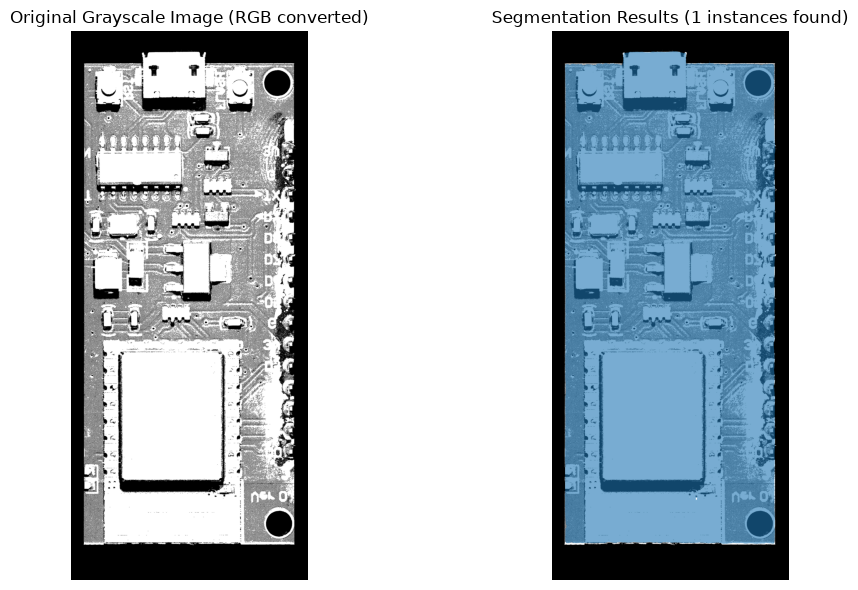

In [50]:
import matplotlib.pyplot as plt
import numpy as np

ALPHA = 0.6

# Bool masks on the GPU first: much less data to copy than float masks
masks = results[0]["masks"].bool().cpu().numpy()          # (N, H, W)
N, H, W = masks.shape

# Same colors as before (one per instance, including empty ones)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, N))[:, :3].astype(np.float32)

# Blend all masks into ONE RGBA layer, in the same order as before.
# The rule "new = a*color + (1-a)*old" is what Matplotlib does when it stacks layers.
prem_rgb = np.zeros((H, W, 3), np.float32)   # color, pre-multiplied by alpha
acc_a    = np.zeros((H, W),    np.float32)   # alpha so far

for i in range(N):
    m = masks[i]
    if not m.any():
        continue
    prem_rgb[m] = ALPHA * colors[i] + (1 - ALPHA) * prem_rgb[m]
    acc_a[m]    = ALPHA + (1 - ALPHA) * acc_a[m]

overlay = np.zeros((H, W, 4), np.float32)
covered = acc_a > 0
overlay[covered, :3] = prem_rgb[covered] / acc_a[covered, None]
overlay[..., 3] = acc_a

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image)
axes[0].set_title("Original Grayscale Image (RGB converted)")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].imshow(overlay)
axes[1].set_title(f"Segmentation Results ({N} instances found)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [61]:
from PIL import Image

# Load the grayscale image and convert it to RGB format
image_path = "images/zil_00-10-83-13-99_261012_112259_Z.png"
image = Image.open(image_path).convert("RGB")   # Converts single channel to 3-channel RGB

# Process the image and prompt
text_prompt = "electronic component"

inputs = processor(images=image, text=text_prompt, return_tensors="pt").to(model.device)

# Run inference
with torch.no_grad():
    outputs = model(**inputs)

# Post-process the results to get segmentation masks
results = processor.post_process_instance_segmentation(
    outputs,
    threshold=0.5,
    target_sizes=[image.size[::-1]]             # image.size returns (width, height), so [::-1] gives (height, width)
)

print("Segmentation complete! Found instances:", len(results[0]["masks"]))

Segmentation complete! Found instances: 25


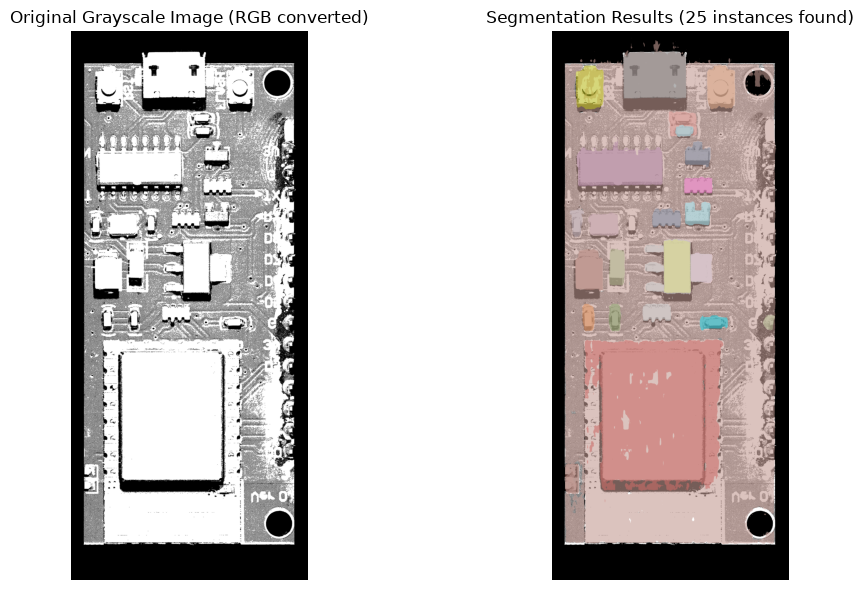

In [62]:
import matplotlib.pyplot as plt
import numpy as np

ALPHA = 0.6

# Bool masks on the GPU first: much less data to copy than float masks
masks = results[0]["masks"].bool().cpu().numpy()          # (N, H, W)
N, H, W = masks.shape

# Same colors as before (one per instance, including empty ones)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, N))[:, :3].astype(np.float32)

# Blend all masks into ONE RGBA layer, in the same order as before.
# The rule "new = a*color + (1-a)*old" is what Matplotlib does when it stacks layers.
prem_rgb = np.zeros((H, W, 3), np.float32)   # color, pre-multiplied by alpha
acc_a    = np.zeros((H, W),    np.float32)   # alpha so far

for i in range(N):
    m = masks[i]
    if not m.any():
        continue
    prem_rgb[m] = ALPHA * colors[i] + (1 - ALPHA) * prem_rgb[m]
    acc_a[m]    = ALPHA + (1 - ALPHA) * acc_a[m]

overlay = np.zeros((H, W, 4), np.float32)
covered = acc_a > 0
overlay[covered, :3] = prem_rgb[covered] / acc_a[covered, None]
overlay[..., 3] = acc_a

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(image)
axes[0].set_title("Original Grayscale Image (RGB converted)")
axes[0].axis("off")

axes[1].imshow(image)
axes[1].imshow(overlay)
axes[1].set_title(f"Segmentation Results ({N} instances found)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

file mode: I;16
presence score: 0.174
top 10 scores: [0.118 0.068 0.068 0.064 0.057 0.054 0.051 0.051 0.047 0.047]
kept 1 instance(s)  (forced top-1, check it!)
best box (px): [90, 225, 2038, 4715]


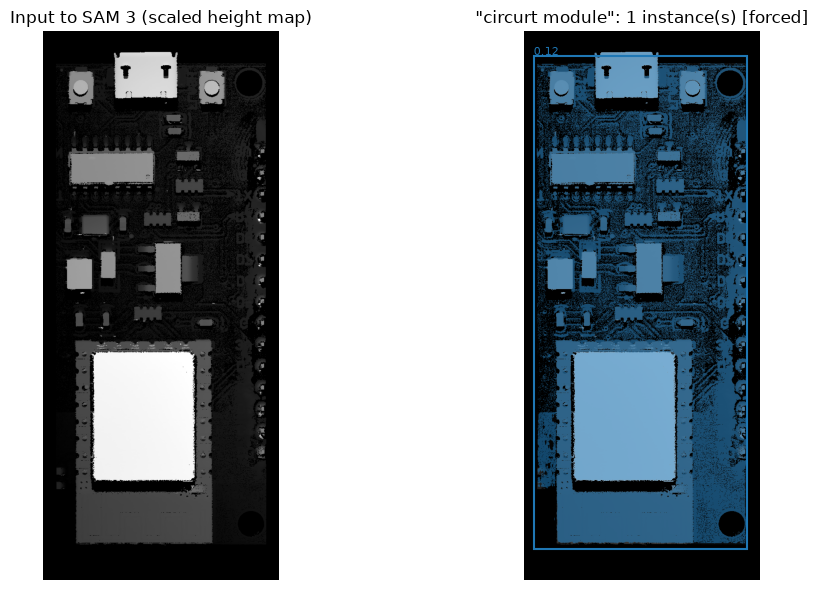

In [79]:
import torch, numpy as np, torch.nn.functional as Fnn
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

# ---------------- Settings ----------------
image_path  = "images/zil_00-10-83-13-99_261012_112259_Z.png"
text_prompt = "circurt module"
example_box = None                      # e.g. [x1, y1, x2, y2] in full-image pixels -> positive example
THR         = 0.5                       # score threshold
REL_THR     = None                      # e.g. 0.5 -> keep scores >= 0.5 * best score (overrides THR)
MIN_ONE     = True                      # if nothing passes, keep the single best candidate
DISPLAY_DIV = 4                         # 1 = full resolution masks; 4 = 1/4 size (faster, less RAM)
ALPHA       = 0.6

# ---------------- 1) Load height map and scale to 0..255 ----------------
raw = Image.open(image_path)
print("file mode:", raw.mode)           # I;16 = 16-bit heights, L = already 8-bit
z = np.array(raw).astype(np.float32)
if z.ndim == 3:                         # already RGB: use one channel
    z = z[..., 0]
valid = z > 0                           # 0 = no data (laser shadow)
lo, hi = np.percentile(z[valid], [1, 99.5])
g = np.clip((z - lo) / (hi - lo), 0, 1)
g[~valid] = 0
image = Image.fromarray((g * 255).astype(np.uint8)).convert("RGB")
W, H = image.size

# ---------------- 2) Run SAM 3 ----------------
proc_kwargs = dict(images=image, text=text_prompt, return_tensors="pt")
if example_box is not None:
    proc_kwargs.update(input_boxes=[[example_box]], input_boxes_labels=[[1]])
inputs = processor(**proc_kwargs).to(model.device)

with torch.inference_mode():
    outputs = model(**inputs)

# Scores = object score x presence score (same formula as the processor)
scores = outputs.pred_logits[0].float().sigmoid()
presence = None
if outputs.presence_logits is not None:
    presence = float(outputs.presence_logits[0].float().sigmoid())
    scores = scores * presence
scores = scores.cpu()

order = scores.argsort(descending=True)
print("presence score:", None if presence is None else round(presence, 3))
print("top 10 scores:", np.round(scores[order[:10]].numpy(), 3))

# ---------------- 3) Choose which instances to keep ----------------
if REL_THR is not None:
    keep = torch.nonzero(scores >= REL_THR * scores.max()).squeeze(1)
else:
    keep = torch.nonzero(scores > THR).squeeze(1)
forced = False
if keep.numel() == 0 and MIN_ONE:
    keep = order[:1]                    # fall back to the best candidate
    forced = True
keep = keep[scores[keep].argsort(descending=True)]   # highest score first
print(f"kept {len(keep)} instance(s)" + ("  (forced top-1, check it!)" if forced else ""))

# Copy what we need to the CPU, then free the GPU
mask_logits = outputs.pred_masks[0, keep].float().cpu()          # (K, h, w), low resolution
boxes_norm  = outputs.pred_boxes[0, keep].float().cpu()          # x1, y1, x2, y2, normalized 0..1
kept_scores = scores[keep]
best_box_px = (outputs.pred_boxes[0, order[0]].float().cpu() * torch.tensor([W, H, W, H])).tolist()
print("best box (px):", [round(v) for v in best_box_px])

del outputs, inputs
torch.cuda.empty_cache()

# ---------------- 4) Scale masks up on the CPU, one at a time ----------------
h, w = H // DISPLAY_DIV, W // DISPLAY_DIV
masks = np.zeros((len(keep), h, w), dtype=bool)
for i in range(len(keep)):
    m = Fnn.interpolate(mask_logits[i][None, None], size=(h, w), mode="bilinear", align_corners=False)
    masks[i] = (m[0, 0] > 0).numpy()                             # logit > 0 == probability > 0.5
masks &= valid[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]             # drop no-data pixels from masks
boxes_px = (boxes_norm * torch.tensor([W, H, W, H])).numpy()     # full-image pixels

# ---------------- 5) Visualize (one overlay layer, fast) ----------------
img_disp = np.asarray(image)[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]
N = len(masks)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(N, 1)))[:, :3].astype(np.float32)

prem = np.zeros((h, w, 3), np.float32)
acc  = np.zeros((h, w), np.float32)
for i in range(N):
    m = masks[i]
    if m.any():
        prem[m] = ALPHA * colors[i] + (1 - ALPHA) * prem[m]
        acc[m]  = ALPHA + (1 - ALPHA) * acc[m]
overlay = np.zeros((h, w, 4), np.float32)
cov = acc > 0
overlay[cov, :3] = prem[cov] / acc[cov, None]
overlay[..., 3] = acc

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_disp)
axes[0].set_title("Input to SAM 3 (scaled height map)")
axes[0].axis("off")

axes[1].imshow(img_disp)
axes[1].imshow(overlay)
s = 1 / DISPLAY_DIV
for i, (x1, y1, x2, y2) in enumerate(boxes_px):
    axes[1].add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                        fill=False, edgecolor=colors[i], linewidth=1.5))
    axes[1].text(x1 * s, y1 * s - 3, f"{kept_scores[i]:.2f}", color=colors[i], fontsize=8)
if example_box is not None:
    x1, y1, x2, y2 = example_box
    axes[1].add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                        fill=False, edgecolor="white", linestyle="--", linewidth=1.5))
axes[1].set_title(f'"{text_prompt}": {N} instance(s)' + (" [forced]" if forced else ""))
axes[1].axis("off")
plt.tight_layout()
plt.show()

file mode: I;16
presence score: 0.938
top 10 scores: [0.761 0.746 0.734 0.733 0.73  0.716 0.712 0.707 0.706 0.695]
kept 27 instance(s)
best box (px): [212, 365, 461, 686]


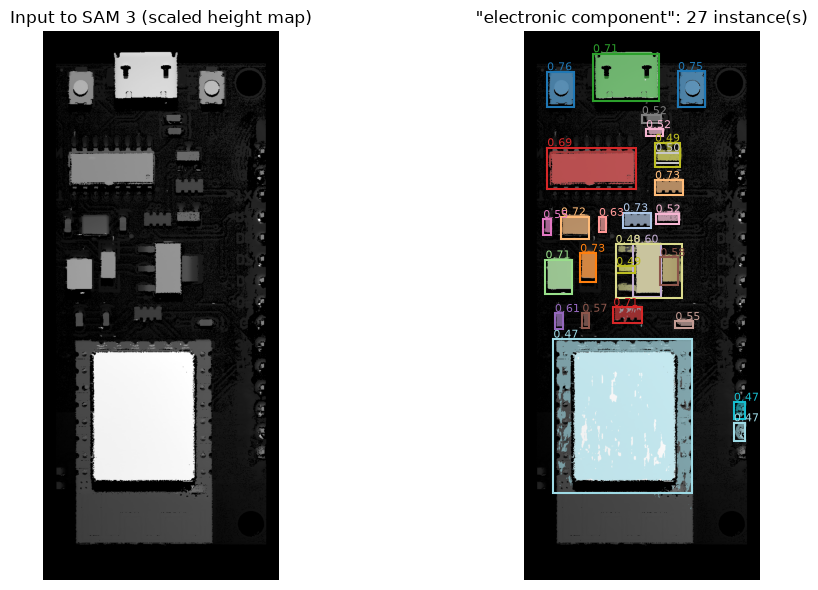

In [82]:
import torch, numpy as np, torch.nn.functional as Fnn
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

# ---------------- Settings ----------------
image_path  = "images/zil_00-10-83-13-99_261012_112259_Z.png"
text_prompt = "electronic component"    # "usb connector", "button"
example_box = None                      # e.g. [x1, y1, x2, y2] in full-image pixels -> positive example
THR         = 0.46                      # score threshold
REL_THR     = None                      # e.g. 0.5 -> keep scores >= 0.5 * best score (overrides THR)
MIN_ONE     = True                      # if nothing passes, keep the single best candidate
DISPLAY_DIV = 4                         # 1 = full resolution masks; 4 = 1/4 size (faster, less RAM)
ALPHA       = 0.6

# ---------------- 1) Load height map and scale to 0..255 ----------------
raw = Image.open(image_path)
print("file mode:", raw.mode)           # I;16 = 16-bit heights, L = already 8-bit
z = np.array(raw).astype(np.float32)
if z.ndim == 3:                         # already RGB: use one channel
    z = z[..., 0]
valid = z > 0                           # 0 = no data (laser shadow)
lo, hi = np.percentile(z[valid], [1, 99.5])
g = np.clip((z - lo) / (hi - lo), 0, 1)
g[~valid] = 0
image = Image.fromarray((g * 255).astype(np.uint8)).convert("RGB")
W, H = image.size

# ---------------- 2) Run SAM 3 ----------------
proc_kwargs = dict(images=image, text=text_prompt, return_tensors="pt")
if example_box is not None:
    proc_kwargs.update(input_boxes=[[example_box]], input_boxes_labels=[[1]])
inputs = processor(**proc_kwargs).to(model.device)

with torch.inference_mode():
    outputs = model(**inputs)

# Scores = object score x presence score (same formula as the processor)
scores = outputs.pred_logits[0].float().sigmoid()
presence = None
if outputs.presence_logits is not None:
    presence = float(outputs.presence_logits[0].float().sigmoid())
    scores = scores * presence
scores = scores.cpu()

order = scores.argsort(descending=True)
print("presence score:", None if presence is None else round(presence, 3))
print("top 10 scores:", np.round(scores[order[:10]].numpy(), 3))

# ---------------- 3) Choose which instances to keep ----------------
if REL_THR is not None:
    keep = torch.nonzero(scores >= REL_THR * scores.max()).squeeze(1)
else:
    keep = torch.nonzero(scores > THR).squeeze(1)
forced = False
if keep.numel() == 0 and MIN_ONE:
    keep = order[:1]                    # fall back to the best candidate
    forced = True
keep = keep[scores[keep].argsort(descending=True)]   # highest score first
print(f"kept {len(keep)} instance(s)" + ("  (forced top-1, check it!)" if forced else ""))

# Copy what we need to the CPU, then free the GPU
mask_logits = outputs.pred_masks[0, keep].float().cpu()          # (K, h, w), low resolution
boxes_norm  = outputs.pred_boxes[0, keep].float().cpu()          # x1, y1, x2, y2, normalized 0..1
kept_scores = scores[keep]
best_box_px = (outputs.pred_boxes[0, order[0]].float().cpu() * torch.tensor([W, H, W, H])).tolist()
print("best box (px):", [round(v) for v in best_box_px])

del outputs, inputs
torch.cuda.empty_cache()

# ---------------- 4) Scale masks up on the CPU, one at a time ----------------
h, w = H // DISPLAY_DIV, W // DISPLAY_DIV
masks = np.zeros((len(keep), h, w), dtype=bool)
for i in range(len(keep)):
    m = Fnn.interpolate(mask_logits[i][None, None], size=(h, w), mode="bilinear", align_corners=False)
    masks[i] = (m[0, 0] > 0).numpy()                             # logit > 0 == probability > 0.5
masks &= valid[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]             # drop no-data pixels from masks
boxes_px = (boxes_norm * torch.tensor([W, H, W, H])).numpy()     # full-image pixels

# ---------------- 5) Visualize (one overlay layer, fast) ----------------
img_disp = np.asarray(image)[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]
N = len(masks)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(N, 1)))[:, :3].astype(np.float32)

prem = np.zeros((h, w, 3), np.float32)
acc  = np.zeros((h, w), np.float32)
for i in range(N):
    m = masks[i]
    if m.any():
        prem[m] = ALPHA * colors[i] + (1 - ALPHA) * prem[m]
        acc[m]  = ALPHA + (1 - ALPHA) * acc[m]
overlay = np.zeros((h, w, 4), np.float32)
cov = acc > 0
overlay[cov, :3] = prem[cov] / acc[cov, None]
overlay[..., 3] = acc

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_disp)
axes[0].set_title("Input to SAM 3 (scaled height map)")
axes[0].axis("off")

axes[1].imshow(img_disp)
axes[1].imshow(overlay)
s = 1 / DISPLAY_DIV
for i, (x1, y1, x2, y2) in enumerate(boxes_px):
    axes[1].add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                        fill=False, edgecolor=colors[i], linewidth=1.5))
    axes[1].text(x1 * s, y1 * s - 3, f"{kept_scores[i]:.2f}", color=colors[i], fontsize=8)
if example_box is not None:
    x1, y1, x2, y2 = example_box
    axes[1].add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                        fill=False, edgecolor="white", linestyle="--", linewidth=1.5))
axes[1].set_title(f'"{text_prompt}": {N} instance(s)' + (" [forced]" if forced else ""))
axes[1].axis("off")
plt.tight_layout()
plt.show()

file mode: RGB
presence score: 0.3
top 10 scores: [0.275 0.095 0.081 0.052 0.039 0.035 0.034 0.026 0.025 0.024]
kept 1 instance(s)  (forced top-1, check it!)
best box (px): [251, 511, 1081, 1477]


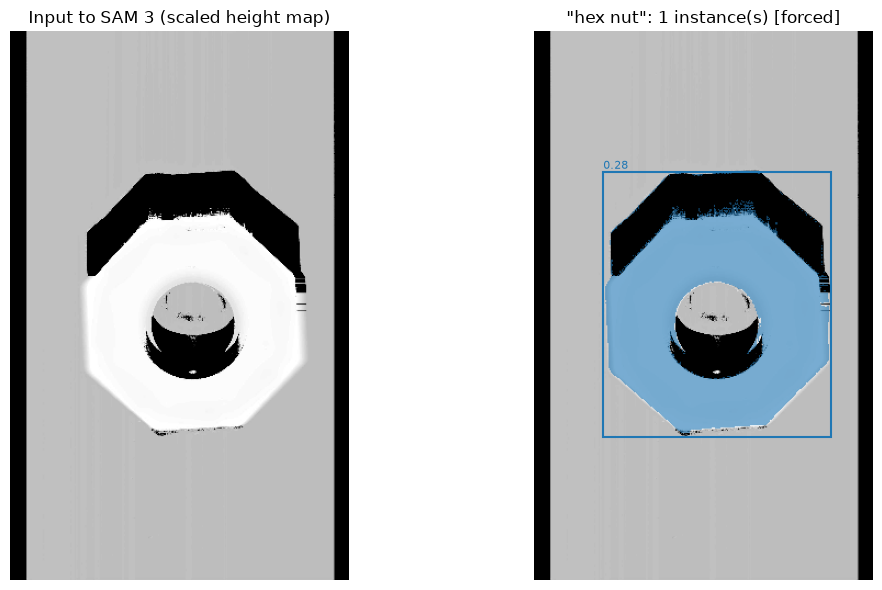

In [ ]:
import torch, numpy as np, torch.nn.functional as Fnn
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

# ---------------- Settings ----------------
image_path  = "images/hex_nut.png"
text_prompt = "hex nut"                 # "foreground object"
example_box = None                      # e.g. [x1, y1, x2, y2] in full-image pixels -> positive example
THR         = 0.46                      # score threshold
REL_THR     = None                      # e.g. 0.5 -> keep scores >= 0.5 * best score (overrides THR)
MIN_ONE     = True                      # if nothing passes, keep the single best candidate
DISPLAY_DIV = 4                         # 1 = full resolution masks; 4 = 1/4 size (faster, less RAM)
ALPHA       = 0.6

# ---------------- 1) Load height map and scale to 0..255 ----------------
raw = Image.open(image_path)
print("file mode:", raw.mode)           # I;16 = 16-bit heights, L = already 8-bit
z = np.array(raw).astype(np.float32)
if z.ndim == 3:                         # already RGB: use one channel
    z = z[..., 0]
valid = z > 0                           # 0 = no data (laser shadow)
lo, hi = np.percentile(z[valid], [1, 99.5])
g = np.clip((z - lo) / (hi - lo), 0, 1)
g[~valid] = 0
image = Image.fromarray((g * 255).astype(np.uint8)).convert("RGB")
W, H = image.size

# ---------------- 2) Run SAM 3 ----------------
proc_kwargs = dict(images=image, text=text_prompt, return_tensors="pt")
if example_box is not None:
    proc_kwargs.update(input_boxes=[[example_box]], input_boxes_labels=[[1]])
inputs = processor(**proc_kwargs).to(model.device)

with torch.inference_mode():
    outputs = model(**inputs)

# Scores = object score x presence score (same formula as the processor)
scores = outputs.pred_logits[0].float().sigmoid()
presence = None
if outputs.presence_logits is not None:
    presence = float(outputs.presence_logits[0].float().sigmoid())
    scores = scores * presence
scores = scores.cpu()

order = scores.argsort(descending=True)
print("presence score:", None if presence is None else round(presence, 3))
print("top 10 scores:", np.round(scores[order[:10]].numpy(), 3))

# ---------------- 3) Choose which instances to keep ----------------
if REL_THR is not None:
    keep = torch.nonzero(scores >= REL_THR * scores.max()).squeeze(1)
else:
    keep = torch.nonzero(scores > THR).squeeze(1)
forced = False
if keep.numel() == 0 and MIN_ONE:
    keep = order[:1]                    # fall back to the best candidate
    forced = True
keep = keep[scores[keep].argsort(descending=True)]   # highest score first
print(f"kept {len(keep)} instance(s)" + ("  (forced top-1, check it!)" if forced else ""))

# Copy what we need to the CPU, then free the GPU
mask_logits = outputs.pred_masks[0, keep].float().cpu()          # (K, h, w), low resolution
boxes_norm  = outputs.pred_boxes[0, keep].float().cpu()          # x1, y1, x2, y2, normalized 0..1
kept_scores = scores[keep]
best_box_px = (outputs.pred_boxes[0, order[0]].float().cpu() * torch.tensor([W, H, W, H])).tolist()
print("best box (px):", [round(v) for v in best_box_px])

del outputs, inputs
torch.cuda.empty_cache()

# ---------------- 4) Scale masks up on the CPU, one at a time ----------------
h, w = H // DISPLAY_DIV, W // DISPLAY_DIV
masks = np.zeros((len(keep), h, w), dtype=bool)
for i in range(len(keep)):
    m = Fnn.interpolate(mask_logits[i][None, None], size=(h, w), mode="bilinear", align_corners=False)
    masks[i] = (m[0, 0] > 0).numpy()                             # logit > 0 == probability > 0.5
masks &= valid[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]             # drop no-data pixels from masks
boxes_px = (boxes_norm * torch.tensor([W, H, W, H])).numpy()     # full-image pixels

# ---------------- 5) Visualize (one overlay layer, fast) ----------------
img_disp = np.asarray(image)[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]
N = len(masks)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(N, 1)))[:, :3].astype(np.float32)

prem = np.zeros((h, w, 3), np.float32)
acc  = np.zeros((h, w), np.float32)
for i in range(N):
    m = masks[i]
    if m.any():
        prem[m] = ALPHA * colors[i] + (1 - ALPHA) * prem[m]
        acc[m]  = ALPHA + (1 - ALPHA) * acc[m]
overlay = np.zeros((h, w, 4), np.float32)
cov = acc > 0
overlay[cov, :3] = prem[cov] / acc[cov, None]
overlay[..., 3] = acc

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img_disp)
axes[0].set_title("Input to SAM 3 (scaled height map)")
axes[0].axis("off")

axes[1].imshow(img_disp)
axes[1].imshow(overlay)
s = 1 / DISPLAY_DIV
for i, (x1, y1, x2, y2) in enumerate(boxes_px):
    axes[1].add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                        fill=False, edgecolor=colors[i], linewidth=1.5))
    axes[1].text(x1 * s, y1 * s - 3, f"{kept_scores[i]:.2f}", color=colors[i], fontsize=8)
if example_box is not None:
    x1, y1, x2, y2 = example_box
    axes[1].add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                        fill=False, edgecolor="white", linestyle="--", linewidth=1.5))
axes[1].set_title(f'"{text_prompt}": {N} instance(s)' + (" [forced]" if forced else ""))
axes[1].axis("off")
plt.tight_layout()
plt.show()